In [1]:
# Import required libraries

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

import librosa
import librosa.display

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score

import seaborn as sns
import os

print("All libraries imported successfully!")
print("NumPy version:", np.__version__)
print("PyTorch version:", torch.__version__)
print("Librosa version:", librosa.__version__)


All libraries imported successfully!
NumPy version: 2.4.6
PyTorch version: 2.14.1+cpu
Librosa version: 0.11.0


In [7]:
# Set random seeds for reproducibility

np.random.seed(42)
torch.manual_seed(42)

print("Random seeds initialized successfully!")

Random seeds initialized successfully!


In [8]:
import numpy as np
import torch
import torch.nn as nn

# -------------------------------
# S1: INITIALIZATION
# -------------------------------

np.random.seed(42)
torch.manual_seed(42)

x1 = np.array([[0.5]])
x2 = np.array([[0.8]])

y = 1
h0 = np.zeros((1, 1))

Wx = np.array([[0.2]])
Wh = np.array([[0.3]])
bh = np.array([[0.1]])

Wo = np.array([[0.4], [-0.2]])
bo = np.array([[0.1], [0.2]])

lr = 0.01

def softmax(z):
    e = np.exp(z - np.max(z))
    return e / np.sum(e)

# -------------------------------
# S2: FORWARD PASS
# -------------------------------

h1 = np.tanh(Wx @ x1 + Wh @ h0 + bh)
h2 = np.tanh(Wx @ x2 + Wh @ h1 + bh)

o2 = Wo @ h2 + bo
y_pred = softmax(o2)

target = np.zeros((2, 1))
target[y] = 1

loss = -np.log(y_pred[y])

print("INITIAL FORWARD PASS")
print("h1 =", h1)
print("h2 =", h2)
print("Output =", o2)
print("Probabilities =", y_pred)
print("Initial Loss =", loss)

# -------------------------------
# S3: BACKPROPAGATION THROUGH TIME
# -------------------------------

do = y_pred.reshape(2, 1) - target

dh2 = Wo.T @ do
delta2 = dh2 * (1 - h2**2)

dh1 = Wh.T @ delta2
delta1 = dh1 * (1 - h1**2)

dWo = do @ h2.T
dbo = do

dWx = delta1 @ x1.T + delta2 @ x2.T
dWh = delta1 @ h0.T + delta2 @ h1.T
dbh = delta1 + delta2

print("\nNUMPY GRADIENTS")
for name, grad in [
    ("dWx", dWx), ("dWh", dWh),
    ("dbh", dbh), ("dWo", dWo), ("dbo", dbo)
]:
    print(name, "=", grad)

# -------------------------------
# S4: SGD PARAMETER UPDATE
# -------------------------------

Wx -= lr * dWx
Wh -= lr * dWh
bh -= lr * dbh
Wo -= lr * dWo
bo -= lr * dbo

# Calculate updated loss
h1_new = np.tanh(Wx @ x1 + Wh @ h0 + bh)
h2_new = np.tanh(Wx @ x2 + Wh @ h1_new + bh)

o2_new = Wo @ h2_new + bo
y_pred_new = softmax(o2_new)

new_loss = -np.log(y_pred_new[y])

print("\nUPDATED PARAMETERS")
print("Wx =", Wx)
print("Wh =", Wh)
print("bh =", bh)
print("Wo =", Wo)
print("bo =", bo)

print("\nLoss before update =", loss)
print("Loss after update =", new_loss)

# -------------------------------
# S5: PYTORCH IMPLEMENTATION
# -------------------------------

# Use the original parameters for a fair comparison
Wx0 = np.array([[0.2]])
Wh0 = np.array([[0.3]])
bh0 = np.array([[0.1]])
Wo0 = np.array([[0.4], [-0.2]])
bo0 = np.array([[0.1], [0.2]])

rnn = nn.RNN(1, 1, num_layers=1, nonlinearity='tanh')
fc = nn.Linear(1, 2)

# Freeze initial weights into PyTorch
with torch.no_grad():
    rnn.weight_ih_l0.copy_(torch.tensor(Wx0, dtype=torch.float32))
    rnn.weight_hh_l0.copy_(torch.tensor(Wh0, dtype=torch.float32))
    rnn.bias_ih_l0.copy_(torch.tensor(bh0.flatten(), dtype=torch.float32))
    rnn.bias_hh_l0.zero_()

    fc.weight.copy_(torch.tensor(Wo0, dtype=torch.float32))
    fc.bias.copy_(torch.tensor(bo0.flatten(), dtype=torch.float32))

# Prevent duplicate bias updates
rnn.bias_hh_l0.requires_grad_(False)

X = torch.tensor([[[0.5]], [[0.8]]], dtype=torch.float32)
target_torch = torch.tensor([1])

output, hidden = rnn(X)
logits = fc(output[-1])

criterion = nn.CrossEntropyLoss()
loss_torch = criterion(logits, target_torch)

print("\nPYTORCH FORWARD PASS")
print("Hidden states =", output.detach().numpy())
print("Logits =", logits.detach().numpy())
print("Loss =", loss_torch.item())

# -------------------------------
# S6: PYTORCH BACKWARD PASS
# -------------------------------

loss_torch.backward()

print("\nPYTORCH GRADIENTS")
print("dWx =", rnn.weight_ih_l0.grad)
print("dWh =", rnn.weight_hh_l0.grad)
print("dbh =", rnn.bias_ih_l0.grad)
print("dWo =", fc.weight.grad)
print("dbo =", fc.bias.grad)

# SGD update
optimizer = torch.optim.SGD(
    list(rnn.parameters()) + list(fc.parameters()),
    lr=lr
)

optimizer.step()

with torch.no_grad():
    output_after, _ = rnn(X)
    logits_after = fc(output_after[-1])
    updated_loss = criterion(logits_after, target_torch)

print("\nPYTORCH LOSS AFTER UPDATE =", updated_loss.item())
print("\nRNN IMPLEMENTATION COMPLETED!")

INITIAL FORWARD PASS
h1 = [[0.19737532]]
h2 = [[0.30879477]]
Output = [[0.22351791]
 [0.13824105]]
Probabilities = [[0.52130631]
 [0.47869369]]
Initial Loss = [0.73669436]

NUMPY GRADIENTS
dWx = [[0.26715712]]
dWh = [[0.05584903]]
dbh = [[0.36453913]]
dWo = [[ 0.16097666]
 [-0.16097666]]
dbo = [[ 0.52130631]
 [-0.52130631]]

UPDATED PARAMETERS
Wx = [[0.19732843]]
Wh = [[0.29944151]]
bh = [[0.09635461]]
Wo = [[ 0.39839023]
 [-0.19839023]]
bo = [[0.09478694]
 [0.20521306]]

Loss before update = [0.73669436]
Loss after update = [0.72870346]

PYTORCH FORWARD PASS
Hidden states = [[[0.19737533]]

 [[0.3087948 ]]]
Logits = [[0.22351792 0.13824104]]
Loss = 0.7366943359375

PYTORCH GRADIENTS
dWx = tensor([[0.2672]])
dWh = tensor([[0.0558]])
dbh = tensor([0.3645])
dWo = tensor([[ 0.1610],
        [-0.1610]])
dbo = tensor([ 0.5213, -0.5213])

PYTORCH LOSS AFTER UPDATE = 0.7287034392356873

RNN IMPLEMENTATION COMPLETED!


In [22]:
from google.colab import drive
drive.mount('/content/drive')
import os
import zipfile

zip_path = None

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'speech_commands_small.zip' in files:
        zip_path = os.path.join(root, 'speech_commands_small.zip')
        break

if zip_path is None:
    raise FileNotFoundError("speech_commands_small.zip not found in MyDrive")

print("ZIP found:", zip_path)

DATASET_PATH = "/content/speech_commands_small"
os.makedirs(DATASET_PATH, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(DATASET_PATH)

print("Extraction completed!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP found: /content/drive/MyDrive/speech_commands_small.zip
Extraction completed!


In [23]:
for root, dirs, files in os.walk(DATASET_PATH):
    print(root, "->", len(files), "files")
classes = ["one", "two", "three", "right", "left"]

audio_files = []
labels = []

for label, word in enumerate(classes):

    folder = None

    for root, dirs, files in os.walk(DATASET_PATH):
        if os.path.basename(root).lower() == word:
            folder = root
            break

    if folder is None:
        raise FileNotFoundError(f"Could not find folder: {word}")

    wav_files = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith(".wav")
    ]

    audio_files.extend(wav_files)
    labels.extend([label] * len(wav_files))

    print(f"{word}: {len(wav_files)} files")

print("\nTotal audio files:", len(audio_files))

/content/speech_commands_small -> 0 files
/content/speech_commands_small/speech_commands_small -> 0 files
/content/speech_commands_small/speech_commands_small/right -> 200 files
/content/speech_commands_small/speech_commands_small/left -> 200 files
/content/speech_commands_small/speech_commands_small/two -> 200 files
/content/speech_commands_small/speech_commands_small/one -> 200 files
/content/speech_commands_small/speech_commands_small/three -> 200 files
one: 200 files
two: 200 files
three: 200 files
right: 200 files
left: 200 files

Total audio files: 1000


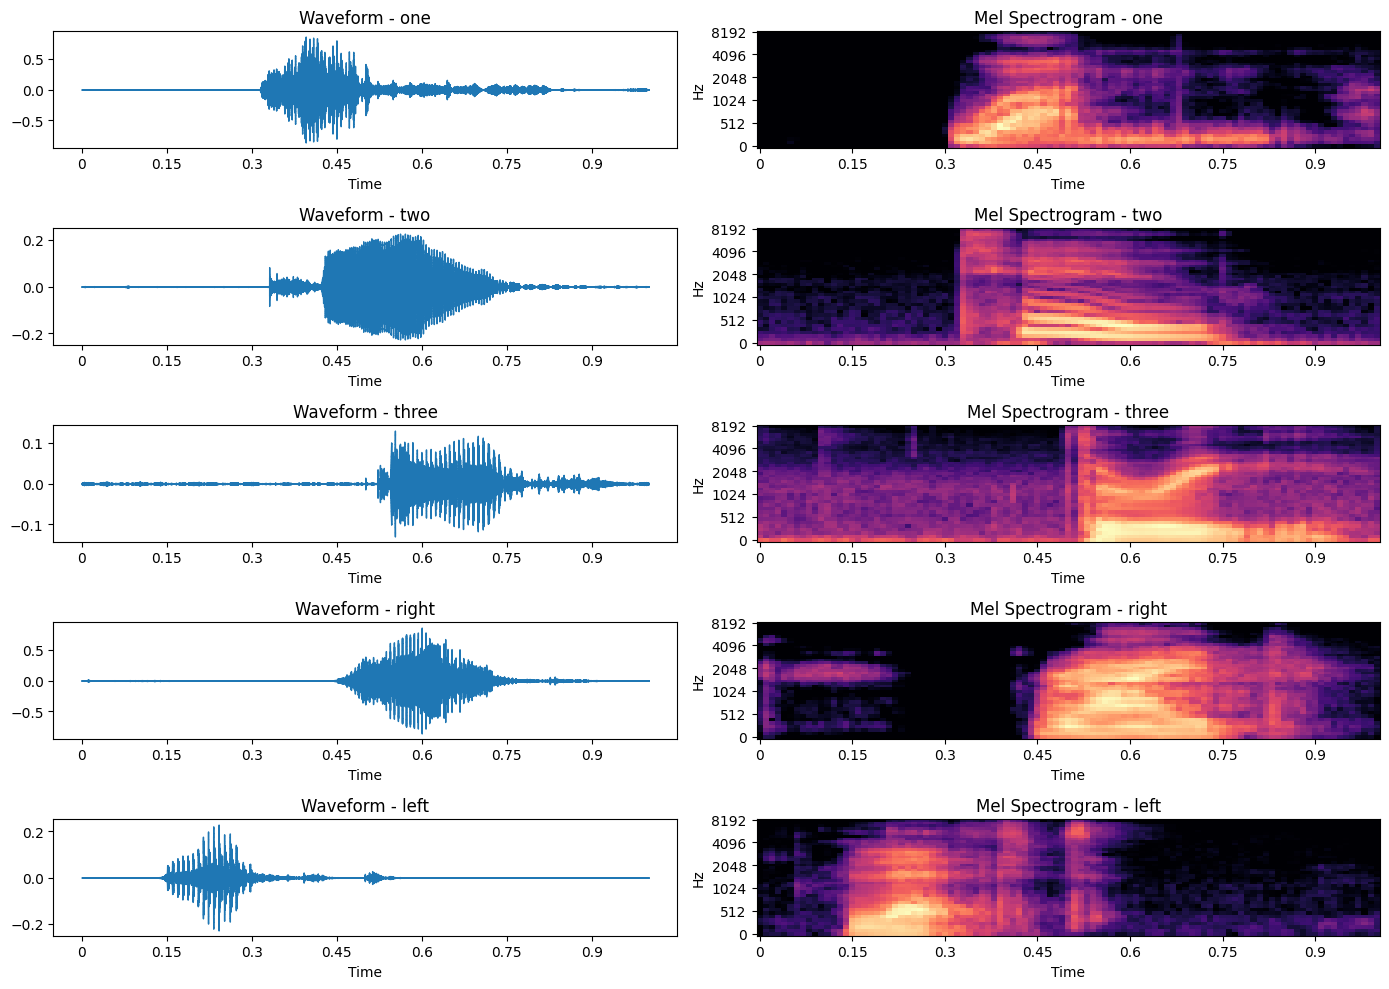

Training: 700
Validation: 150
Testing: 150


In [24]:
DATASET_PATH = "/content/speech_commands_small/speech_commands_small"
plt.figure(figsize=(14, 10))

for i, word in enumerate(classes):
    idx = labels.index(i)

    audio, sr = librosa.load(audio_files[idx], sr=16000)

    plt.subplot(5, 2, 2*i + 1)
    librosa.display.waveshow(audio, sr=sr)
    plt.title(f"Waveform - {word}")

    mel = librosa.feature.melspectrogram(
        y=audio, sr=sr, n_fft=400,
        hop_length=160, n_mels=40
    )

    mel_db = librosa.power_to_db(mel, ref=np.max)

    plt.subplot(5, 2, 2*i + 2)
    librosa.display.specshow(
        mel_db, sr=sr, hop_length=160,
        x_axis="time", y_axis="mel"
    )
    plt.title(f"Mel Spectrogram - {word}")

plt.tight_layout()
plt.savefig("rnn_spectrograms.png")
plt.show()
from sklearn.model_selection import train_test_split

X_train_files, X_temp_files, y_train, y_temp = train_test_split(
    audio_files, labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

X_val_files, X_test_files, y_val, y_test = train_test_split(
    X_temp_files, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train_files))
print("Validation:", len(X_val_files))
print("Testing:", len(X_test_files))


In [25]:
def extract_mfcc(path):
    audio, sr = librosa.load(path, sr=16000, mono=True)

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13,
        n_fft=400,
        hop_length=160,
        win_length=400
    )

    return mfcc.T

X_train_raw = [extract_mfcc(f) for f in X_train_files]
X_val_raw = [extract_mfcc(f) for f in X_val_files]
X_test_raw = [extract_mfcc(f) for f in X_test_files]

print("MFCC extraction completed.")
print("One sample shape:", X_train_raw[0].shape)
mean = np.concatenate(X_train_raw, axis=0).mean(axis=0)
std = np.concatenate(X_train_raw, axis=0).std(axis=0) + 1e-8

def prepare_data(data, max_len=100):
    result = []

    for seq in data:
        seq = (seq - mean) / std

        if len(seq) > max_len:
            seq = seq[:max_len]
        else:
            padding = np.zeros((max_len - len(seq), 13))
            seq = np.vstack((seq, padding))

        result.append(seq)

    return np.array(result, dtype=np.float32)

X_train = prepare_data(X_train_raw)
X_val = prepare_data(X_val_raw)
X_test = prepare_data(X_test_raw)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

MFCC extraction completed.
One sample shape: (101, 13)
Training shape: (700, 100, 13)
Validation shape: (150, 100, 13)
Testing shape: (150, 100, 13)


In [26]:
from torch.utils.data import Dataset, DataLoader

class SpeechDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(
    SpeechDataset(X_train, y_train),
    batch_size=32, shuffle=True
)

val_loader = DataLoader(
    SpeechDataset(X_val, y_val),
    batch_size=32, shuffle=False
)

test_loader = DataLoader(
    SpeechDataset(X_test, y_test),
    batch_size=32, shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [28]:
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

class RNNClassifier(nn.Module):
    def __init__(self):
        super(RNNClassifier, self).__init__()

        self.rnn = nn.RNN(
            input_size=13,
            hidden_size=64,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(64, 5)

    def forward(self, x):
        output, hidden = self.rnn(x)
        final_output = output[:, -1, :]
        return self.fc(final_output)

rnn_model = RNNClassifier().to(device)

print(rnn_model)


Device: cpu
RNNClassifier(
  (rnn): RNN(13, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=5, bias=True)
)


In [29]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(rnn_model.parameters(), lr=0.001)

epochs = 10

train_accuracies = []
val_accuracies = []
train_losses = []

for epoch in range(epochs):

    rnn_model.train()
    correct = 0
    total = 0
    running_loss = 0

    for inputs, targets in train_loader:

        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = rnn_model(inputs)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        predicted = torch.argmax(outputs, dim=1)
        total += targets.size(0)
        correct += (predicted == targets).sum().item()

    train_accuracy = 100 * correct / total
    train_loss = running_loss / len(train_loader)

    # Validation
    rnn_model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, targets in val_loader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = rnn_model(inputs)
            predicted = torch.argmax(outputs, dim=1)

            total += targets.size(0)
            correct += (predicted == targets).sum().item()

    val_accuracy = 100 * correct / total

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)
    train_losses.append(train_loss)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

Epoch 1/10 | Loss: 1.6111 | Train Accuracy: 20.71% | Validation Accuracy: 26.00%
Epoch 2/10 | Loss: 1.5817 | Train Accuracy: 28.29% | Validation Accuracy: 28.67%
Epoch 3/10 | Loss: 1.5610 | Train Accuracy: 28.57% | Validation Accuracy: 30.00%
Epoch 4/10 | Loss: 1.5018 | Train Accuracy: 34.00% | Validation Accuracy: 37.33%
Epoch 5/10 | Loss: 1.5031 | Train Accuracy: 34.14% | Validation Accuracy: 40.67%
Epoch 6/10 | Loss: 1.4606 | Train Accuracy: 36.71% | Validation Accuracy: 45.33%
Epoch 7/10 | Loss: 1.4309 | Train Accuracy: 38.14% | Validation Accuracy: 42.00%
Epoch 8/10 | Loss: 1.4332 | Train Accuracy: 37.14% | Validation Accuracy: 36.00%
Epoch 9/10 | Loss: 1.4184 | Train Accuracy: 37.14% | Validation Accuracy: 41.33%
Epoch 10/10 | Loss: 1.4177 | Train Accuracy: 39.29% | Validation Accuracy: 44.00%


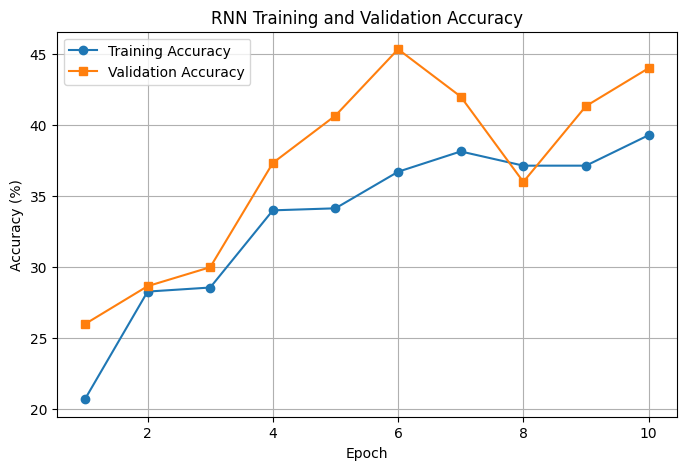

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, epochs+1), train_accuracies,
         marker='o', label="Training Accuracy")

plt.plot(range(1, epochs+1), val_accuracies,
         marker='s', label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("RNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.savefig("rnn_accuracy.png")
plt.show()

In [31]:
from sklearn.metrics import accuracy_score, confusion_matrix

rnn_model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():
    for inputs, targets in test_loader:

        inputs = inputs.to(device)

        outputs = rnn_model(inputs)
        predicted = torch.argmax(outputs, dim=1)

        all_predictions.extend(predicted.cpu().numpy())
        all_targets.extend(targets.numpy())

test_accuracy = accuracy_score(all_targets, all_predictions)

print(f"RNN Test Accuracy: {test_accuracy * 100:.2f}%")


RNN Test Accuracy: 40.00%


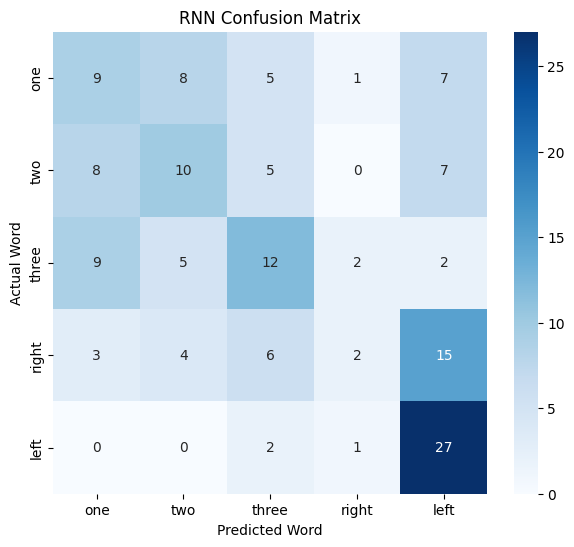

In [32]:
import seaborn as sns

cm = confusion_matrix(
    all_targets,
    all_predictions,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Word")
plt.ylabel("Actual Word")
plt.title("RNN Confusion Matrix")

plt.savefig("rnn_confusion_matrix.png")
plt.show()

In [33]:
torch.save(rnn_model.state_dict(), "rnn_model.pth")

print("RNN model saved successfully!")

RNN model saved successfully!


In [34]:
import numpy as np
import torch
import torch.nn as nn

np.set_printoptions(precision=6, suppress=True)

# Input sequence
x = [
    np.array([[0.5]]),
    np.array([[0.8]])
]

# Initial hidden and cell states
h = np.zeros((1, 1))
c = np.zeros((1, 1))

# Gate weights: [hidden state, input]
Wf = np.array([[0.2, 0.3]])
Wi = np.array([[0.1, 0.4]])
Wc = np.array([[0.3, 0.2]])
Wo = np.array([[0.2, 0.1]])

# Biases
bf = np.array([[0.1]])
bi = np.array([[0.1]])
bc = np.array([[0.0]])
bo = np.array([[0.1]])

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [35]:
hidden_states = []
cell_states = []

for t in range(2):

    combined = np.vstack((h, x[t]))

    # Forget gate
    f = sigmoid(Wf @ combined + bf)

    # Input gate
    i = sigmoid(Wi @ combined + bi)

    # Candidate cell state
    C_candidate = np.tanh(Wc @ combined + bc)

    # Updated cell state
    c = f * c + i * C_candidate

    # Output gate
    o = sigmoid(Wo @ combined + bo)

    # Updated hidden state
    h = o * np.tanh(c)

    hidden_states.append(h.copy())
    cell_states.append(c.copy())

    print(f"\nTime Step {t+1}")
    print("Forget Gate:", f)
    print("Input Gate:", i)
    print("Candidate Cell:", C_candidate)
    print("Cell State:", c)
    print("Output Gate:", o)
    print("Hidden State:", h)


Time Step 1
Forget Gate: [[0.562177]]
Input Gate: [[0.574443]]
Candidate Cell: [[0.099668]]
Cell State: [[0.057254]]
Output Gate: [[0.53743]]
Hidden State: [[0.030736]]

Time Step 2
Forget Gate: [[0.585683]]
Input Gate: [[0.604219]]
Candidate Cell: [[0.167624]]
Cell State: [[0.134814]]
Output Gate: [[0.546403]]
Hidden State: [[0.07322]]


In [36]:
Wy = np.array([[0.5]])
by = np.array([[0.1]])

prediction = sigmoid(Wy @ h + by)

target = 1

bce_loss = -np.log(prediction[0, 0] + 1e-8)

print("Final Prediction:", prediction)
print("Target:", target)
print("Binary Cross Entropy Loss:", bce_loss)
lstm = nn.LSTM(
    input_size=1,
    hidden_size=1,
    num_layers=1,
    batch_first=False
)

with torch.no_grad():

    lstm.weight_ih_l0.copy_(
        torch.tensor([[0.4], [0.3], [0.2], [0.1]], dtype=torch.float32)
    )

    lstm.weight_hh_l0.copy_(
        torch.tensor([[0.1], [0.2], [0.3], [0.2]], dtype=torch.float32)
    )

    lstm.bias_ih_l0.copy_(
        torch.tensor([0.1, 0.1, 0.0, 0.1], dtype=torch.float32)
    )

    lstm.bias_hh_l0.zero_()

# Input shape: (sequence length, batch size, input size)
X_lstm = torch.tensor(
    [[[0.5]], [[0.8]]],
    dtype=torch.float32
)

output, (h_n, c_n) = lstm(X_lstm)

print("PyTorch Hidden States:")
print(output.detach().numpy())

print("\nPyTorch Final Cell State:")
print(c_n.detach().numpy())

print("\nPyTorch Final Hidden State:")
print(h_n.detach().numpy())


Final Prediction: [[0.534099]]
Target: 1
Binary Cross Entropy Loss: 0.6271732191457235
PyTorch Hidden States:
[[[0.030736]]

 [[0.07322 ]]]

PyTorch Final Cell State:
[[[0.134814]]]

PyTorch Final Hidden State:
[[[0.07322]]]


In [37]:
numpy_hidden = np.array(hidden_states).reshape(2, 1)
numpy_cell = np.array(cell_states).reshape(2, 1)

torch_hidden = output.detach().numpy().reshape(2, 1)
torch_cell = c_n.detach().numpy().reshape(1, 1)

print("NumPy Hidden States:")
print(numpy_hidden)

print("\nPyTorch Hidden States:")
print(torch_hidden)

print("\nHidden State Difference:")
print(np.abs(numpy_hidden - torch_hidden))

print("\nNumPy Final Cell State:")
print(numpy_cell[-1])

print("\nPyTorch Final Cell State:")
print(torch_cell[0])

print("\nMaximum Hidden State Error:",
      np.max(np.abs(numpy_hidden - torch_hidden)))

print("\nMaximum Cell State Error:",
      np.max(np.abs(numpy_cell[-1] - torch_cell[0])))

NumPy Hidden States:
[[0.030736]
 [0.07322 ]]

PyTorch Hidden States:
[[0.030736]
 [0.07322 ]]

Hidden State Difference:
[[0.]
 [0.]]

NumPy Final Cell State:
[0.134814]

PyTorch Final Cell State:
[0.134814]

Maximum Hidden State Error: 3.6767183880792587e-09

Maximum Cell State Error: 2.5806503600733777e-09


In [38]:
class LSTMClassifier(nn.Module):
    def __init__(self):
        super(LSTMClassifier, self).__init__()

        self.projection = nn.Linear(13, 64)

        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=64,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(64, 5)

    def forward(self, x):
        x = self.projection(x)

        output, (hidden, cell) = self.lstm(x)

        final_hidden = hidden[-1]

        return self.fc(final_hidden)


lstm_model = LSTMClassifier().to(device)

print(lstm_model)


LSTMClassifier(
  (projection): Linear(in_features=13, out_features=64, bias=True)
  (lstm): LSTM(64, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=5, bias=True)
)


In [39]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

epochs = 10

lstm_train_accuracies = []
lstm_val_accuracies = []
lstm_train_losses = []

for epoch in range(epochs):

    # Training
    lstm_model.train()

    correct = 0
    total = 0
    running_loss = 0

    for inputs, targets in train_loader:

        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = lstm_model(inputs)

        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        predicted = torch.argmax(outputs, dim=1)

        total += targets.size(0)
        correct += (predicted == targets).sum().item()

    train_accuracy = 100 * correct / total
    train_loss = running_loss / len(train_loader)

    # Validation
    lstm_model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for inputs, targets in val_loader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = lstm_model(inputs)

            predicted = torch.argmax(outputs, dim=1)

            total += targets.size(0)
            correct += (predicted == targets).sum().item()

    val_accuracy = 100 * correct / total

    lstm_train_accuracies.append(train_accuracy)
    lstm_val_accuracies.append(val_accuracy)
    lstm_train_losses.append(train_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {train_loss:.4f} "
        f"Train Accuracy: {train_accuracy:.2f}% "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/10] Loss: 1.6058 Train Accuracy: 21.43% Validation Accuracy: 18.00%
Epoch [2/10] Loss: 1.5751 Train Accuracy: 25.43% Validation Accuracy: 26.67%
Epoch [3/10] Loss: 1.5368 Train Accuracy: 28.71% Validation Accuracy: 28.67%
Epoch [4/10] Loss: 1.4341 Train Accuracy: 35.71% Validation Accuracy: 41.33%
Epoch [5/10] Loss: 1.4358 Train Accuracy: 41.14% Validation Accuracy: 40.67%
Epoch [6/10] Loss: 1.3975 Train Accuracy: 40.14% Validation Accuracy: 44.00%
Epoch [7/10] Loss: 1.3431 Train Accuracy: 43.14% Validation Accuracy: 44.67%
Epoch [8/10] Loss: 1.3404 Train Accuracy: 42.29% Validation Accuracy: 44.00%
Epoch [9/10] Loss: 1.2841 Train Accuracy: 46.29% Validation Accuracy: 44.00%
Epoch [10/10] Loss: 1.2553 Train Accuracy: 48.14% Validation Accuracy: 44.67%


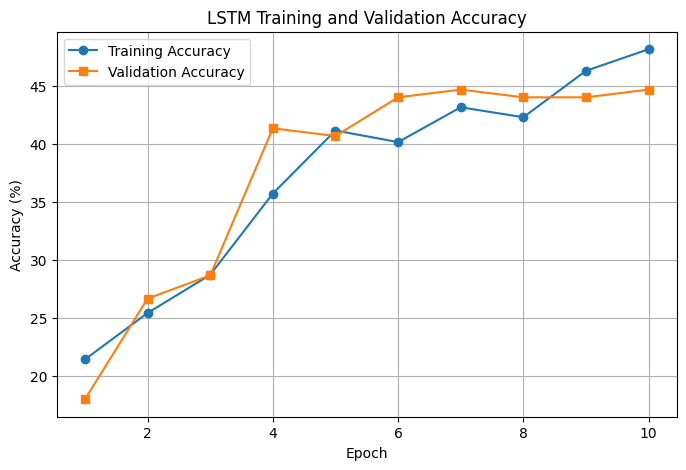

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs+1),
    lstm_train_accuracies,
    marker='o',
    label="Training Accuracy"
)

plt.plot(
    range(1, epochs+1),
    lstm_val_accuracies,
    marker='s',
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("LSTM Training and Validation Accuracy")

plt.legend()
plt.grid(True)

plt.savefig("lstm_accuracy.png")
plt.show()

In [41]:
from sklearn.metrics import accuracy_score, confusion_matrix

lstm_model.eval()

lstm_predictions = []
lstm_targets = []

with torch.no_grad():

    for inputs, targets in test_loader:

        inputs = inputs.to(device)

        outputs = lstm_model(inputs)

        predicted = torch.argmax(outputs, dim=1)

        lstm_predictions.extend(predicted.cpu().numpy())
        lstm_targets.extend(targets.numpy())

lstm_test_accuracy = accuracy_score(
    lstm_targets,
    lstm_predictions
)

print(
    f"LSTM Test Accuracy: "
    f"{lstm_test_accuracy * 100:.2f}%"
)

LSTM Test Accuracy: 42.67%


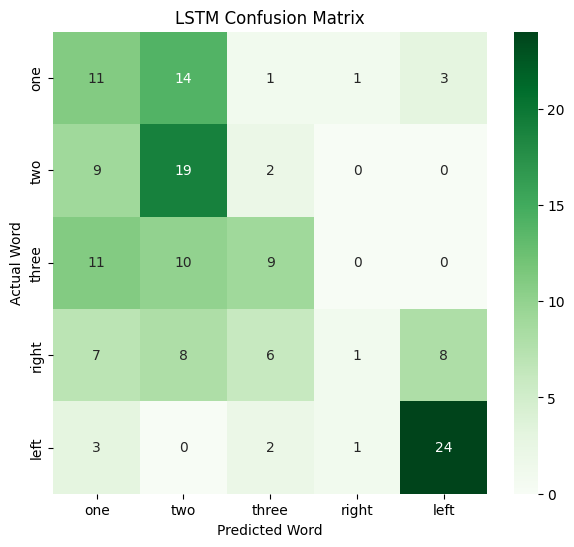

In [42]:
cm_lstm = confusion_matrix(
    lstm_targets,
    lstm_predictions,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Word")
plt.ylabel("Actual Word")
plt.title("LSTM Confusion Matrix")

plt.savefig("lstm_confusion_matrix.png")
plt.show()

In [43]:
torch.save(
    lstm_model.state_dict(),
    "lstm_model.pth"
)

print("LSTM model saved successfully!")

LSTM model saved successfully!


MODEL PERFORMANCE COMPARISON
--------------------------------
RNN Test Accuracy  : 40.00%
LSTM Test Accuracy : 42.67%


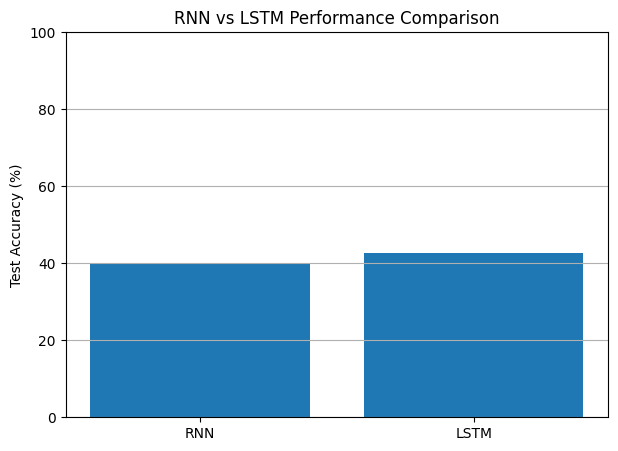

In [44]:
print("MODEL PERFORMANCE COMPARISON")
print("--------------------------------")

print(f"RNN Test Accuracy  : {test_accuracy * 100:.2f}%")
print(f"LSTM Test Accuracy : {lstm_test_accuracy * 100:.2f}%")

models = ["RNN", "LSTM"]
accuracies = [
    test_accuracy * 100,
    lstm_test_accuracy * 100
]

plt.figure(figsize=(7, 5))

plt.bar(models, accuracies)

plt.ylabel("Test Accuracy (%)")
plt.title("RNN vs LSTM Performance Comparison")
plt.ylim(0, 100)
plt.grid(axis="y")

plt.savefig("rnn_lstm_comparison.png")
plt.show()

In [45]:
import zipfile
import os

result_files = [
    "rnn_spectrograms.png",
    "rnn_accuracy.png",
    "rnn_confusion_matrix.png",
    "rnn_model.pth",
    "lstm_accuracy.png",
    "lstm_confusion_matrix.png",
    "lstm_model.pth",
    "rnn_lstm_comparison.png"
]

with zipfile.ZipFile("Lab5_Results.zip", "w") as zipf:

    for file in result_files:
        if os.path.exists(file):
            zipf.write(file)

print("Lab5_Results.zip created successfully!")

Lab5_Results.zip created successfully!
